# 82514 · Sesión S11 — Singularidades y elipsoide de manipulabilidad

**Bloque 4** · lunes 26 de octubre de 2026 · 2 h  ·  IQS Universitat Ramon Llull

**Qué hace este cuaderno.** Localiza las singularidades del 2R plano de la clase (a1 = 0,35 m, a2 = 0,2 m) y del brazo clásico de seis ejes siguiendo el determinante del jacobiano a lo largo de barridos articulares, dibuja el elipsoide de manipulabilidad en dos posturas —la del ejemplo de clase y otra casi estirada— y cuantifica la diferencia con las dos medidas escalares del bloque: la de Yoshikawa y el número de condición.

**Se apoya en:** Lynch y Park (2017), cap. 5 — elipsoide de manipulabilidad y su colapso a un segmento (p. 173), cociente de semiejes como número de condición (p. 174), definición de singularidad cinemática como pérdida de rango de J (p. 191), independencia de la elección de marcos (pp. 192-193) y catálogo de casos en robots 6R (pp. 193-195); Corke (2023), cap. 8 — hiperelipsoide en el espacio de velocidades de la tarea (pp. 316-317), elipsoides traslacional y rotacional por separado (pp. 317-318), medida de Yoshikawa y el método manipulability (p. 319), la Yoshikawa mide volumen y no isotropía (p. 328), singularidad de muñeca con la quinta articulación a cero (p. 282) y caída de manipulabilidad en trayectoria cartesiana (p. 289).

**Cómo usarlo en clase.** Sigue el guion de la sesión S11 en las diapositivas del bloque 4. Ejecuta la celda de instalación una sola vez al empezar; en Colab tarda varios minutos. Las celdas marcadas **Ejercicio** son para que los trabajen los estudiantes: las soluciones están al final del cuaderno.

---

In [1]:
# Ejecutar una sola vez. En Colab tarda varios minutos.
import importlib, subprocess, sys

def asegurar(mods):
    faltan = []
    for pip_name, import_name in mods:
        try:
            importlib.import_module(import_name)
        except ImportError:
            faltan.append(pip_name)
    if faltan:
        print('Instalando:', ' '.join(faltan))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + faltan, check=False)
    else:
        print('Todo instalado ya.')

asegurar([('numpy', 'numpy'), ('matplotlib', 'matplotlib'), ('spatialmath-python', 'spatialmath'), ('roboticstoolbox-python==1.4.4', 'roboticstoolbox')])

import numpy as np
import matplotlib.pyplot as plt
import roboticstoolbox as rtb
from spatialmath import SE3

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (9, 3.4)
plt.rcParams['axes.grid'] = True
IQS_AZUL, IQS_VERDE = '#1B2A80', '#1FA355'
print('roboticstoolbox', rtb.__version__, '- listo.')

Instalando: spatialmath-python roboticstoolbox-python==1.4.4
roboticstoolbox 1.4.4 - listo.


> **Aviso para Colab.** `roboticstoolbox-python` **tarda varios minutos** en instalarse la primera vez: lanza la celda de instalación al abrir el cuaderno (en clase, antes del descanso). Mientras corre, Colab deja en cola cualquier otra celda, también las del 2R, que usan `np`, `plt` y los colores que define esa misma celda: aprovecha para leer la sección 1. La celda instala la versión 1.4.4 de la toolbox y la imprime al terminar. Como en las sesiones anteriores, **nada de `robot.plot()` ni `robot.teach()`**: los elipsoides los dibujamos nosotros con matplotlib, que además obliga a entender de dónde salen.

## 1. El determinante del jacobiano a lo largo de un barrido articular

Una singularidad cinemática es una postura en la que el efector pierde capacidad instantánea de movimiento: «el jacobiano permite identificar posturas en las que el efector del robot pierde la capacidad de moverse instantáneamente en una o más direcciones. Tal postura se denomina singularidad cinemática, o simplemente singularidad. **Matemáticamente, una postura singular es aquella en la que el jacobiano J(q) deja de tener rango máximo**» (Lynch y Park, 2017, p. 191).

Para un robot con J cuadrado, «rango no máximo» equivale a determinante nulo. La forma más directa de localizar las singularidades del 2R es barrer el espacio articular y mirar `det J`. El 2R es el de todo el bloque: `a1 = 0,35 m` y `a2 = 0,2 m`.

Para el 2R plano el determinante tiene una forma cerrada preciosa: `det J = a1·a2·sin(q2)`. **No depende de q1 en absoluto** —girar el hombro reorienta el brazo entero pero no cambia su geometría interna— y se anula en `q2 = 0` (brazo estirado) y `q2 = ±180°` (brazo replegado sobre sí mismo). En la postura del ejemplo de clase, `q = (1,0°; 74,5°)`, vale 0,067 m², cerca de su máximo, `a1·a2 = 0,07 m²`.

Junto al determinante, la figura del barrido dibuja el **número de condición** de J (`np.linalg.cond`), κ en las diapositivas: el cociente entre el semieje mayor y el menor de la elipse de velocidades de la mano del cuaderno S11a, cuántas veces más hay que mover las articulaciones para mover la mano en la peor dirección que en la mejor. Lo ideal es 1. Esos dos semiejes se llaman **valores singulares** de J, y la sección 2 los estudia.

In [2]:
A1, A2 = 0.35, 0.2     # el 2R del bloque, en metros

def jac_2r(q, a1=A1, a2=A2):
    q1, q2 = q
    s1, c1 = np.sin(q1), np.cos(q1)
    s12, c12 = np.sin(q1+q2), np.cos(q1+q2)
    return np.array([[-a1*s1 - a2*s12, -a2*s12],
                     [ a1*c1 + a2*c12,  a2*c12]])

q2s = np.linspace(-np.pi, np.pi, 721)
dets = np.array([np.linalg.det(jac_2r([0.4, q2])) for q2 in q2s])
teorico = A1 * A2 * np.sin(q2s)
print('¿det J == a1·a2·sin(q2)?', np.allclose(dets, teorico))

# ¿depende de q1? Con el codo del ejemplo de clase, q2 = 74,46 grados
q2_ej = np.deg2rad(74.46)
for q1_grados in [1.04, 30, 90, 150, -45]:
    d = np.linalg.det(jac_2r([np.deg2rad(q1_grados), q2_ej]))
    print(f'  q1 = {q1_grados:6.2f} grados, q2 = 74.46 grados  ->  det J = {d:.6f}')
print(f'Siempre {A1*A2*np.sin(q2_ej):.3f} m^2, el det J del ejemplo de clase; su maximo es a1·a2 = {A1*A2:.2f} m^2.')
print('El determinante no depende de q1: la singularidad es una propiedad de la FORMA del brazo.')

¿det J == a1·a2·sin(q2)? True
  q1 =   1.04 grados, q2 = 74.46 grados  ->  det J = 0.067441
  q1 =  30.00 grados, q2 = 74.46 grados  ->  det J = 0.067441
  q1 =  90.00 grados, q2 = 74.46 grados  ->  det J = 0.067441
  q1 = 150.00 grados, q2 = 74.46 grados  ->  det J = 0.067441
  q1 = -45.00 grados, q2 = 74.46 grados  ->  det J = 0.067441
Siempre 0.067 m^2, el det J del ejemplo de clase; su maximo es a1·a2 = 0.07 m^2.
El determinante no depende de q1: la singularidad es una propiedad de la FORMA del brazo.


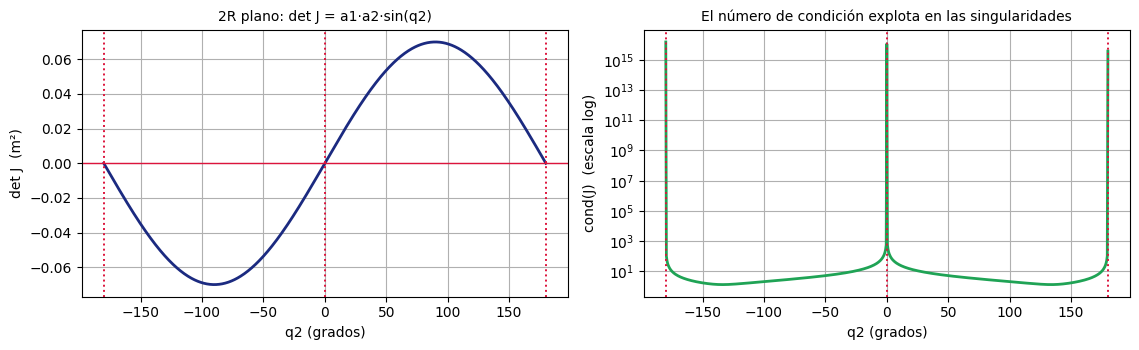

Fuera de las singularidades el numero de condicion es de unas pocas unidades;
a 1 grado del brazo estirado ya vale 280.


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6))

a1.plot(np.rad2deg(q2s), dets, color=IQS_AZUL, lw=2)
a1.axhline(0, color='crimson', lw=1)
for q_sing in [-180, 0, 180]:
    a1.axvline(q_sing, color='crimson', ls=':', lw=1.4)
a1.set_xlabel('q2 (grados)'); a1.set_ylabel('det J  (m²)')
a1.set_title('2R plano: det J = a1·a2·sin(q2)', fontsize=10)

conds = np.array([np.linalg.cond(jac_2r([0.4, q2])) for q2 in q2s])
a2.semilogy(np.rad2deg(q2s), conds, color=IQS_VERDE, lw=2)
for q_sing in [-180, 0, 180]:
    a2.axvline(q_sing, color='crimson', ls=':', lw=1.4)
a2.set_xlabel('q2 (grados)'); a2.set_ylabel('cond(J)  (escala log)')
a2.set_title('El número de condición explota en las singularidades', fontsize=10)
plt.tight_layout(); plt.show()

print('Fuera de las singularidades el numero de condicion es de unas pocas unidades;')
print(f'a 1 grado del brazo estirado ya vale {np.linalg.cond(jac_2r([0.4, np.deg2rad(1)])):.0f}.')

**El punto que hay que dejar claro.** El determinante se anula *exactamente* en la singularidad, pero eso no es lo que importa en la práctica: nadie manda un robot exactamente a `q2 = 0`. Lo que importa es la **vecindad**, donde el número de condición ya vale cientos y la velocidad resuelta del cuaderno S11a pide velocidades articulares desmesuradas. Por eso los controladores industriales reducen velocidad o rechazan la trayectoria mucho antes de llegar al punto singular.

Y una propiedad estructural que conviene subrayar: la definición «es independiente de la elección de jacobiano en el espacio o en el cuerpo» y las singularidades «son también independientes de la elección de marco fijo y de marco del efector» (Lynch y Park, 2017, pp. 192-193). **Cambiar el marco equivale a recolocar el robot, y recolocar un robot no puede cambiar sus singularidades.** En el cuaderno S11a vimos que `jacob0` y `jacobe` son el mismo J expresado en dos marcos; aquí comprobamos que dan el mismo determinante en el brazo clásico de seis ejes. En el cuaderno se llama `robot`: es el modelo del brazo clásico de la toolbox.

In [4]:
robot = rtb.models.DH.Puma560()     # el modelo del brazo clasico de seis ejes de la toolbox
q_muneca = np.array([0, 0.5, -1.0, 0.7, 0.0, 0.3])   # q5 = 0 (en Python, q[4] = 0)

for etq, q in [('qn', robot.qn), ('qr', robot.qr), ('muñeca singular (q5=0)', q_muneca)]:
    d0 = np.linalg.det(robot.jacob0(q))
    de = np.linalg.det(robot.jacobe(q))
    print(f'{etq:>24}:  det jacob0 = {d0:11.6f}   det jacobe = {de:11.6f}   '
          f'iguales? {np.isclose(d0, de)}')

# tol=1e-9: una direccion en la que la mano se mueve menos de una milmillonesima
# por rad/s cuenta como perdida; el redondeo nunca da un cero exacto
print('\nRango del jacobiano en la muñeca singular:',
      np.linalg.matrix_rank(robot.jacob0(q_muneca), tol=1e-9), 'de 6')
print('-> ha perdido una direccion: con q5 = 0 los ejes 4 y 6 quedan en linea.')
print('   Es la singularidad de muñeca de S10 (Corke, 2023, p. 282).')

                      qn:  det jacob0 =   -0.078617   det jacobe =   -0.078617   iguales? True
                      qr:  det jacob0 =    0.000000   det jacobe =    0.000000   iguales? True
  muñeca singular (q5=0):  det jacob0 =    0.000000   det jacobe =    0.000000   iguales? True

Rango del jacobiano en la muñeca singular: 5 de 6
-> ha perdido una direccion: con q5 = 0 los ejes 4 y 6 quedan en linea.
   Es la singularidad de muñeca de S10 (Corke, 2023, p. 282).


### Ejercicio 1

Barre `q5` del seis ejes de −100 a 100 grados (sus límites) manteniendo el resto en `qn` (en Python es `q[4]`, porque se cuenta desde 0), y dibuja `|det(robot.jacob0(q))|` en escala logarítmica. ¿Dónde está el mínimo y cuánto vale el determinante allí? Comprueba el rango de J en ese punto con `np.linalg.matrix_rank`. Fuera del mínimo, divide `det J` entre `sin(q5)`: ¿qué sale?

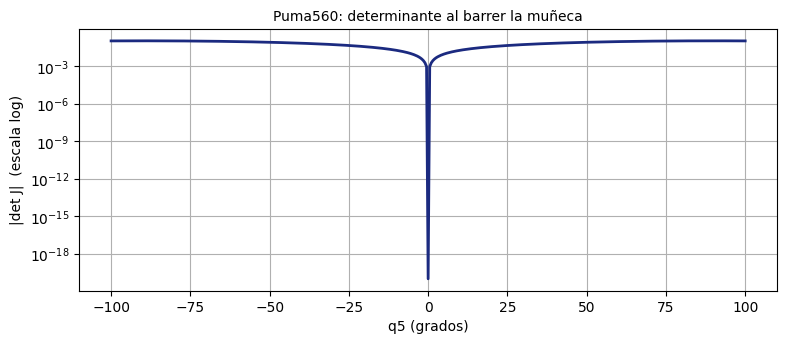

Mínimo en q5 = 0.0 grados, |det J| = 0.0e+00
Rango de J con q5 = 0: 5 de 6
Columna 4: [ 0.     0.     0.     0.707 -0.    -0.707]
Columna 6: [ 0.     0.     0.     0.707 -0.    -0.707] -> iguales: ejes 4 y 6 alineados
det J / sin(q5) = [-0.1112]


In [5]:
# Ejercicio 1
q5s = np.deg2rad(np.linspace(-100, 100, 401))

# barrer q5 (q[4] en Python) con el resto en qn
dets_q5 = []
for q5 in q5s:
    q = robot.qn.copy()
    q[4] = q5
    dets_q5.append(np.linalg.det(robot.jacob0(q)))
dets_q5 = np.array(dets_q5)

plt.semilogy(np.rad2deg(q5s), np.abs(dets_q5) + 1e-20, color=IQS_AZUL, lw=2)
plt.xlabel('q5 (grados)'); plt.ylabel('|det J|  (escala log)')
plt.title('Puma560: determinante al barrer la muñeca', fontsize=10)
plt.show()

# dónde está el mínimo
i_min = np.abs(dets_q5).argmin()
print(f'Mínimo en q5 = {np.rad2deg(q5s[i_min]):.1f} grados, |det J| = {abs(dets_q5[i_min]):.1e}')

# rango de J en ese punto
q = robot.qn.copy(); q[4] = 0.0
J = robot.jacob0(q)
print('Rango de J con q5 = 0:', np.linalg.matrix_rank(J, tol=1e-9), 'de 6')
print('Columna 4:', J[:, 3].round(3))
print('Columna 6:', J[:, 5].round(3), '-> iguales: ejes 4 y 6 alineados')

# det J / sin(q5) fuera del mínimo
fuera = np.abs(np.sin(q5s)) > 1e-3
print('det J / sin(q5) =', np.unique(np.round(dets_q5[fuera] / np.sin(q5s[fuera]), 4)))

## 2. El elipsoide de manipulabilidad

Para cuantificar la proximidad a una singularidad se estudia **cómo J deforma las velocidades**. Considérese el conjunto de velocidades articulares de esfuerzo unidad, `q̇ᵀq̇ = 1`: su imagen a través del jacobiano es un elipsoide en el espacio de velocidades del efector, «el elipsoide de manipulabilidad» (Lynch y Park, 2017, p. 173). En la formulación de Corke, las velocidades de la mano `v` que cumplen `vᵀ·(J·Jᵀ)⁻¹·v = 1` forman «un hiperelipsoide en el espacio de velocidades de la tarea», idealmente próximo a esférico —isótropo— y con radios del mismo orden (Corke, 2023, pp. 316-317).

La construcción se hace con la descomposición en valores singulares `J = U·Σ·Vᵀ`: **las direcciones principales del elipsoide son las columnas de U y los semiejes son los valores singulares**. Interpretación directa: el semieje mayor es la dirección en la que el efector se mueve con más facilidad; el menor, la dirección difícil.

«Según la configuración del manipulador se aproxima a una singularidad, el elipsoide colapsa a un segmento» (Lynch y Park, 2017, p. 173). Lo vemos en el 2R en las dos posturas de clase: la del ejemplo, `q = (1,0°; 74,5°)`, y una casi estirada, con `q2 = 10°`.

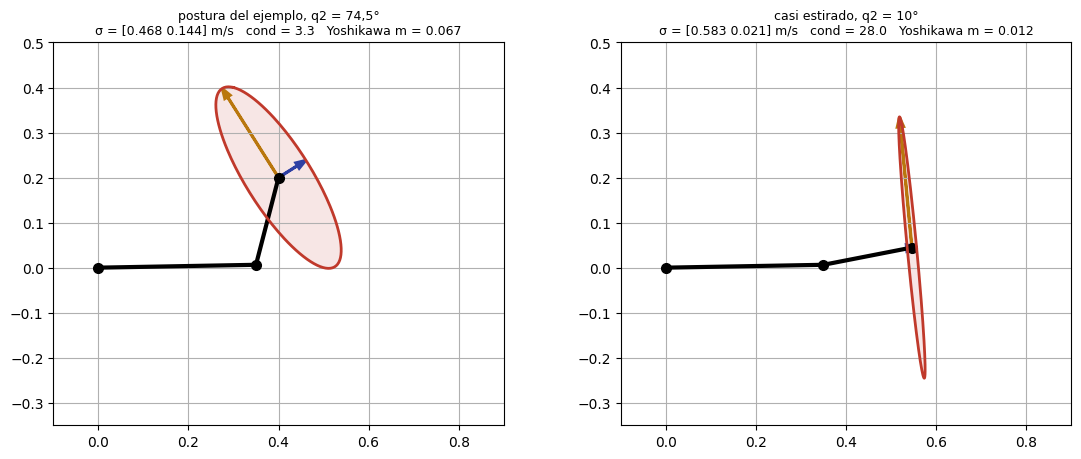

 postura del ejemplo, q2 = 74,5°:  sigma = [0.468 0.144] m/s   cond =  3.3   m = 0.067
         casi estirado, q2 = 10°:  sigma = [0.583 0.021] m/s   cond = 28.0   m = 0.012
En ambar el semieje mayor (direccion facil), en azul el menor (direccion dificil), como en las diapositivas.


In [6]:
def elipse_manipulabilidad(J, n=200):
    """Contorno del elipsoide de manipulabilidad 2D: imagen del circulo unidad de q_dot."""
    th = np.linspace(0, 2*np.pi, n)
    return J @ np.vstack([np.cos(th), np.sin(th)])

def puntos_2r(q, a1=A1, a2=A2):
    q1, q2 = q
    p0 = np.zeros(2)
    p1 = p0 + a1*np.array([np.cos(q1), np.sin(q1)])
    p2 = p1 + a2*np.array([np.cos(q1+q2), np.sin(q1+q2)])
    return np.vstack([p0, p1, p2])

posturas = [(np.deg2rad([1.04, 74.46]), 'postura del ejemplo, q2 = 74,5°'),
            (np.deg2rad([1.04, 10.0]),  'casi estirado, q2 = 10°')]
ESC = 0.5     # escala de dibujo: 1 m/s de velocidad de la mano se dibuja como 0,5 m

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
resumen = []
for ax, (q, titulo) in zip(axes, posturas):
    J = jac_2r(q)
    U, S, Vt = np.linalg.svd(J)
    P = puntos_2r(q)
    E = elipse_manipulabilidad(J) * ESC + P[-1][:, None]

    ax.plot(P[:, 0], P[:, 1], 'o-', lw=3, ms=7, color='black')
    ax.plot(E[0], E[1], color='#C0392B', lw=2)              # la elipse, en rojo
    ax.fill(E[0], E[1], color='#C0392B', alpha=0.12)
    for k in range(2):
        v = U[:, k] * S[k] * ESC
        ax.arrow(P[-1, 0], P[-1, 1], v[0], v[1], head_width=0.015,
                 color='#B9770E' if k == 0 else '#2E3FA3',    # sigma1 ambar, sigma2 azul
                 length_includes_head=True, lw=2)
    m = np.sqrt(np.linalg.det(J @ J.T))
    resumen.append((titulo, S, m))
    ax.set_title(f'{titulo}\nσ = {S.round(3)} m/s   cond = {S[0]/S[1]:.1f}   '
                 f'Yoshikawa m = {m:.3f}', fontsize=9)
    ax.set_aspect('equal'); ax.set_xlim(-0.1, 0.9); ax.set_ylim(-0.35, 0.5)
plt.tight_layout(); plt.show()

for titulo, S, m in resumen:
    print(f'{titulo:>32}:  sigma = {S.round(3)} m/s   cond = {S[0]/S[1]:4.1f}   m = {m:.3f}')
print('En ambar el semieje mayor (direccion facil), en azul el menor (direccion dificil), como en las diapositivas.')

En 3D la construcción es la misma: la imagen de la esfera unidad de velocidades articulares. Para robots espaciales el elipsoide completo es 6D y no visualizable, así que se dibujan por separado el **traslacional** y el **rotacional** extrayendo los bloques correspondientes de J (Corke, 2023, pp. 317-318).

Dibujamos el elipsoide traslacional del brazo clásico de seis ejes en dos posturas: `qn`, la nominal del modelo, y la misma con el codo casi recto, `q3 = −80°` (en este modelo el brazo queda recto del todo con `q3 ≈ −87,3°`).

              qn (nominal):  semiejes = [0.69  0.613 0.263] m/s   cond = 2.6
 casi estirado (q3 = -80°):  semiejes = [0.975 0.572 0.024] m/s   cond = 40.2


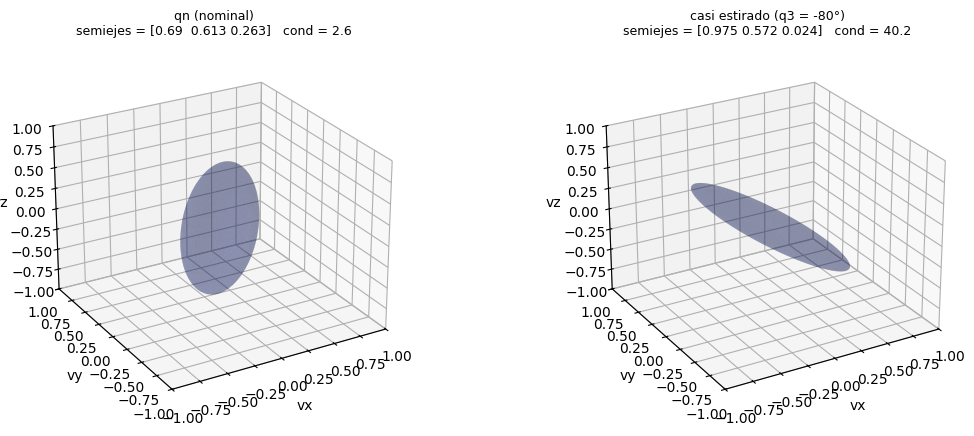

Casi estirado, el elipsoide se aplasta: a lo largo del brazo la mano apenas puede moverse.


In [7]:
def elipsoide(J3, n=40):
    """Malla del elipsoide imagen de la esfera unidad a traves de un bloque 3xn de J."""
    u = np.linspace(0, 2*np.pi, 2*n); v = np.linspace(0, np.pi, n)
    esfera = np.array([np.outer(np.cos(u), np.sin(v)).ravel(),
                       np.outer(np.sin(u), np.sin(v)).ravel(),
                       np.outer(np.ones_like(u), np.cos(v)).ravel()])
    # imagen de la esfera unidad de q_dot: basta la SVD del bloque traslacional
    U, S, _ = np.linalg.svd(J3, full_matrices=False)
    E = U @ np.diag(S) @ esfera
    return [E[k].reshape(2*n, n) for k in range(3)]

q_est = np.deg2rad([0, 45, -80, 0, 45, 0])     # qn con el codo casi recto: brazo casi estirado
fig = plt.figure(figsize=(11, 4.4))
for k, (etq, q) in enumerate([('qn (nominal)', robot.qn), ('casi estirado (q3 = -80°)', q_est)]):
    J = robot.jacob0(q)
    X, Y, Z = elipsoide(J[:3, :])
    ax = fig.add_subplot(1, 2, k+1, projection='3d')
    ax.plot_surface(X, Y, Z, color=IQS_AZUL, alpha=0.28, linewidth=0)
    lim = 1.0
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.view_init(elev=25, azim=-120)     # vista en la que se ve el aplastamiento
    S = np.linalg.svd(J[:3, :], compute_uv=False)
    ax.set_title(f'{etq}\nsemiejes = {S.round(3)}   cond = {S[0]/S[2]:.1f}', fontsize=9)
    ax.set_xlabel('vx'); ax.set_ylabel('vy'); ax.set_zlabel('vz')
    print(f'{etq:>26}:  semiejes = {S.round(3)} m/s   cond = {S[0]/S[2]:.1f}')
fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.02, wspace=0.1)
plt.show()
print('Casi estirado, el elipsoide se aplasta: a lo largo del brazo la mano apenas puede moverse.')

## 3. Las dos medidas escalares: Yoshikawa y número de condición

De la forma del elipsoide se derivan dos números.

**El número de condición geométrico**, κ en las diapositivas, cociente entre los semiejes mayor y menor: cuanto más próximo a 1, más isótropa la postura (Lynch y Park, 2017, p. 174). Mide **forma**.

**La medida de Yoshikawa**, `m(q) = sqrt(det(J(q)·Jᵀ(q)))`, proporcional al volumen del elipsoide y calculada en la toolbox por el método `manipulability` (Corke, 2023, p. 319). Mide **tamaño**. Se anula exactamente en las singularidades, lo que la convierte en un buen indicador para monitorizar trayectorias.

**Aviso de interpretación imprescindible:** «la medida de Yoshikawa es el volumen del elipsoide de velocidad» pero **no mide isotropía**, de modo que un elipsoide muy alargado puede tener buen volumen (Corke, 2023, p. 328). Hay que usar las dos.

In [8]:
def yoshikawa(J):
    return float(np.sqrt(max(0.0, np.linalg.det(J @ J.T))))

# comprobamos que nuestra formula coincide con el metodo de la toolbox
for etq, q in [('qz', robot.qz), ('qn', robot.qn), ('qr', robot.qr), ('casi estirado', q_est)]:
    J = robot.jacob0(q)
    print(f'{etq:>15}:  m a mano = {yoshikawa(J):.6f}   '
          f'robot.manipulability = {robot.manipulability(q):.6f}   '
          f'cond = {np.linalg.cond(J):10.3e}')
print('\nOjo con qz y qr: m = 0 exactamente. Las dos tienen q5 = 0, la muñeca singular:')
print('dos configuraciones con nombre del modelo son SINGULARES, y por eso su numero')
print('de condicion es astronomico.')

print('\n(m es tambien |det J| cuando J es cuadrado:',
      round(abs(np.linalg.det(robot.jacob0(robot.qn))), 6), ')')

             qz:  m a mano = 0.000000   robot.manipulability = 0.000000   cond =  2.949e+17
             qn:  m a mano = 0.078617   robot.manipulability = 0.078617   cond =  7.884e+00
             qr:  m a mano = 0.000000   robot.manipulability = 0.000000   cond =  3.192e+19
  casi estirado:  m a mano = 0.009564   robot.manipulability = 0.009564   cond =  8.600e+01

Ojo con qz y qr: m = 0 exactamente. Las dos tienen q5 = 0, la muñeca singular:
dos configuraciones con nombre del modelo son SINGULARES, y por eso su numero
de condicion es astronomico.

(m es tambien |det J| cuando J es cuadrado: 0.078617 )


Ahora el contraejemplo que hace concreto el aviso de Corke: **dos posturas con volúmenes parecidos y formas radicalmente distintas**. Lo buscamos por fuerza bruta en el 2R, donde todo se puede dibujar.

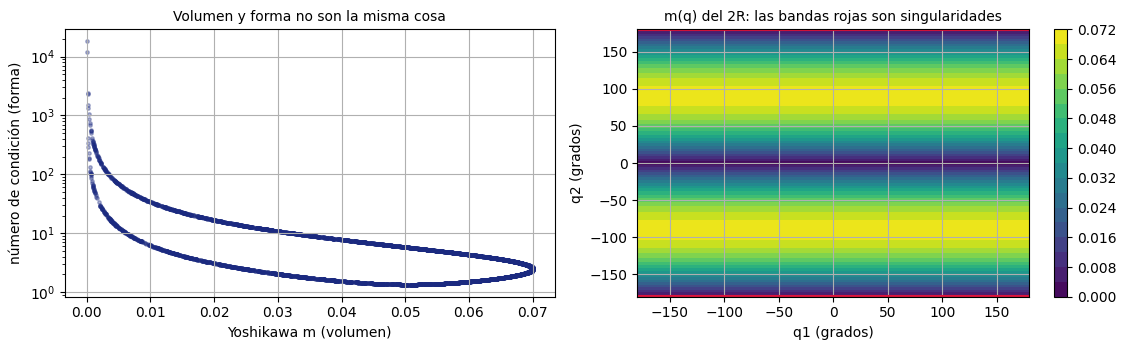

Rango de m: 0.0000 a 0.0700
La postura mas isotropa encontrada tiene cond = 1.349 y m = 0.0505


In [9]:
rng = np.random.default_rng(18)
muestras = []
for _ in range(4000):
    q = np.array([rng.uniform(-np.pi, np.pi), rng.uniform(-np.pi, np.pi)])
    J = jac_2r(q)
    muestras.append((q, yoshikawa(J), np.linalg.cond(J)))

m_vals = np.array([s[1] for s in muestras])
c_vals = np.array([s[2] for s in muestras])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax1.scatter(m_vals, c_vals, s=6, color=IQS_AZUL, alpha=0.35)
ax1.set_yscale('log'); ax1.set_xlabel('Yoshikawa m (volumen)')
ax1.set_ylabel('número de condición (forma)')
ax1.set_title('Volumen y forma no son la misma cosa', fontsize=10)

# mapa de m(q) sobre el espacio articular del 2R
Q1, Q2 = np.meshgrid(np.linspace(-np.pi, np.pi, 160), np.linspace(-np.pi, np.pi, 160))
M = A1 * A2 * np.abs(np.sin(Q2))
c = ax2.contourf(np.rad2deg(Q1), np.rad2deg(Q2), M, levels=18, cmap='viridis')
ax2.contour(np.rad2deg(Q1), np.rad2deg(Q2), M, levels=[1e-3], colors='crimson')
ax2.set_xlabel('q1 (grados)'); ax2.set_ylabel('q2 (grados)')
ax2.set_title('m(q) del 2R: las bandas rojas son singularidades', fontsize=10)
plt.colorbar(c, ax=ax2)
plt.tight_layout(); plt.show()

print(f'Rango de m: {m_vals.min():.4f} a {m_vals.max():.4f}')
print(f'La postura mas isotropa encontrada tiene cond = {c_vals.min():.3f} '
      f'y m = {m_vals[c_vals.argmin()]:.4f}')

### Ejercicio 2

En el mapa de `m(q)` del 2R, las singularidades son las bandas horizontales `q2 = 0` y `q2 = ±180°`. Encuentra numéricamente el `q2` **más isótropo** (el de menor número de condición) barriendo `q2` en (0, 180°). ¿Sale `q2 = 90°`, como sugiere la intuición del «brazo en L»? Repite con eslabones iguales, `a1 = a2 = 0.35`, y con un segundo eslabón corto, `a1 = 0.35, a2 = 0.1`, y explica qué cambia.

### Ejercicio 3

Calcula la medida de Yoshikawa del brazo de seis ejes (`robot`) sobre 2000 configuraciones aleatorias dentro de sus límites articulares y dibuja el histograma. ¿Qué fracción de configuraciones tiene `m` por debajo del 10 % del máximo encontrado? Ese porcentaje es una estimación cruda de «cuánto del espacio articular es zona mala».

    eslabones de clase: a2 = 0.200  ->  cond mínimo = 1.349 en q2 = 133.7°
     eslabones iguales: a2 = 0.350  ->  cond mínimo = 1.618 en q2 = 131.8°
 segundo eslabón corto: a2 = 0.100  ->  cond mínimo = 3.237 en q2 = 119.4°
            a2 = a1/√2: a2 = 0.247  ->  cond mínimo = 1.000 en q2 = 135.0°


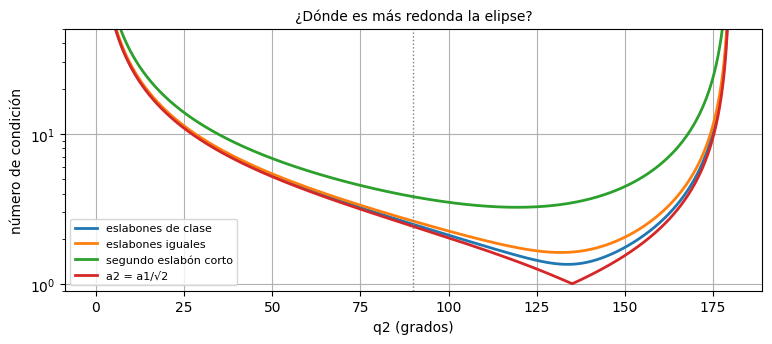

In [10]:
# Ejercicio 2
def cond_2r(q2, a1=A1, a2=A2):
    return np.linalg.cond(jac_2r([0.0, q2], a1, a2))   # q1 no importa

q2_fino = np.deg2rad(np.linspace(0.1, 179.9, 17981))   # pasos de 0,01°

casos = [(0.35, 0.2,  'eslabones de clase'),
         (0.35, 0.35, 'eslabones iguales'),
         (0.35, 0.1,  'segundo eslabón corto'),
         (0.35, 0.35/np.sqrt(2), 'a2 = a1/√2')]

for a1, a2, nombre in casos:
    c = np.array([cond_2r(q2, a1, a2) for q2 in q2_fino])
    q2_opt = np.rad2deg(q2_fino[c.argmin()])
    print(f'{nombre:>22}: a2 = {a2:.3f}  ->  cond mínimo = {c.min():.3f} en q2 = {q2_opt:.1f}°')
    plt.semilogy(np.rad2deg(q2_fino), c, lw=2, label=nombre)

plt.axvline(90, color='gray', ls=':', lw=1)
plt.xlabel('q2 (grados)'); plt.ylabel('número de condición')
plt.ylim(0.9, 50); plt.legend(fontsize=8)
plt.title('¿Dónde es más redonda la elipse?', fontsize=10)
plt.show()

## 4. Manipulabilidad a lo largo de un camino del seis ejes

El uso operativo de `m(q)` es monitorizar una trayectoria y ver si pasa cerca de una zona mala. En el ejemplo del libro, una trayectoria cartesiana del brazo clásico resuelta con cinemática inversa analítica ve caer su manipulabilidad casi a cero por la singularidad de muñeca (Corke, 2023, p. 289). Aquí hacemos algo parecido con un camino articular sencillo, una recta entre dos posturas sanas, y lo retomaremos en S12 con trayectorias de verdad.

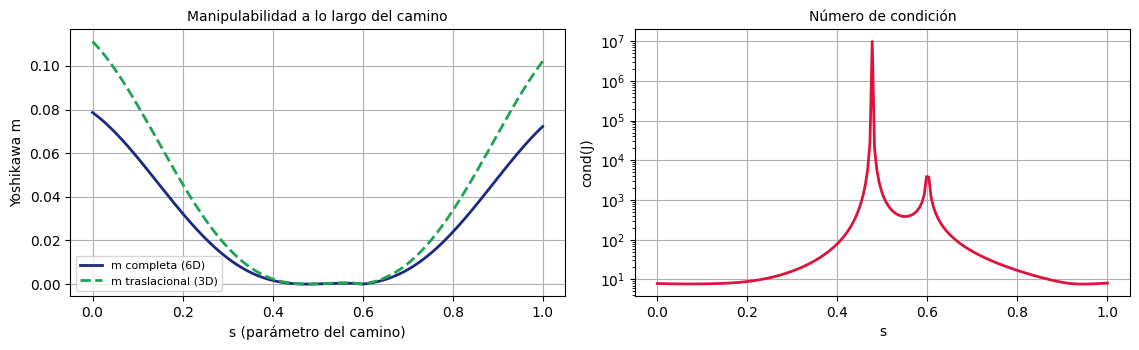

En los extremos: m(qn) = 0.0786   m(q_fin) = 0.0722   (dos posturas sanas)
Minimo de m en s = 0.477:  m = 1.093e-08   cond = 9.870e+06
Ahi el codo vale q3 = 92.7 grados: el brazo, replegado sobre si mismo,
como el 2R con q2 = 180 grados.
Segundo pico de cond en s = 0.598: el centro de la muñeca pasa a 0.150 m
del eje 1, justo el desplazamiento lateral del hombro: la singularidad de hombro.

La manipulabilidad no baja: se ANULA. Este camino, que parece inocente porque
es una recta en el espacio articular entre dos posturas sanas, ATRAVIESA la zona
singular. Nadie lo habria adivinado mirando los dos extremos.


In [11]:
# camino articular: interpolamos linealmente entre qn y otra postura sana
q_fin = np.array([0.0, -0.2, -0.05, 0.0, np.pi/4, 0.0])   # el codo, doblado al otro lado
s = np.linspace(0, 1, 200)
camino = np.array([(1-si)*robot.qn + si*q_fin for si in s])

m = np.array([robot.manipulability(q) for q in camino])
cond = np.array([np.linalg.cond(robot.jacob0(q)) for q in camino])
m_trans = np.array([yoshikawa(robot.jacob0(q)[:3, :]) for q in camino])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
a1.plot(s, m, color=IQS_AZUL, lw=2, label='m completa (6D)')
a1.plot(s, m_trans, color=IQS_VERDE, lw=2, ls='--', label='m traslacional (3D)')
a1.set_xlabel('s (parámetro del camino)'); a1.set_ylabel('Yoshikawa m')
a1.legend(fontsize=8); a1.set_title('Manipulabilidad a lo largo del camino', fontsize=10)

a2.semilogy(s, cond, color='crimson', lw=2)
a2.set_xlabel('s'); a2.set_ylabel('cond(J)'); a2.set_title('Número de condición', fontsize=10)
plt.tight_layout(); plt.show()

j = int(m.argmin())
print(f'En los extremos: m(qn) = {m[0]:.4f}   m(q_fin) = {m[-1]:.4f}   (dos posturas sanas)')
print(f'Minimo de m en s = {s[j]:.3f}:  m = {m[j]:.3e}   cond = {cond[j]:.3e}')
print(f'Ahi el codo vale q3 = {np.rad2deg(camino[j, 2]):.1f} grados: el brazo, replegado sobre si mismo,')
print('como el 2R con q2 = 180 grados.')

k = j + 20 + int(cond[j+20:].argmax())     # el segundo pico de cond, despues del primero
p = robot.fkine(camino[k]).t                # en este modelo, el centro de la muñeca
print(f'Segundo pico de cond en s = {s[k]:.3f}: el centro de la muñeca pasa a {np.hypot(p[0], p[1]):.3f} m')
print('del eje 1, justo el desplazamiento lateral del hombro: la singularidad de hombro.')
print('\nLa manipulabilidad no baja: se ANULA. Este camino, que parece inocente porque')
print('es una recta en el espacio articular entre dos posturas sanas, ATRAVIESA la zona')
print('singular. Nadie lo habria adivinado mirando los dos extremos.')

**El mensaje de cierre para la clase.** La singularidad no es una avería sino una **propiedad geométrica anticipable**: está escrita en la tabla DH del robot antes de que nadie lo encienda. Y la primera herramienta para evitarla no es el algoritmo de control, es el **diseño de la tarea**: dónde se coloca la pieza respecto del robot, con qué orientación se presenta la herramienta, por qué zona del espacio de trabajo se pide que pase la trayectoria.

Un robot bien colocado no necesita ninguna estrategia sofisticada de evitación de singularidades. Uno mal colocado no hay estrategia que lo salve.

---

## Soluciones

**Ejercicio 1.** El mínimo está en `q5 = 0` (`q[4] = 0` en Python), donde `|det J|` cae varios órdenes de magnitud —numéricamente queda en el nivel del redondeo, del orden de 1e-18— y `np.linalg.matrix_rank(J, tol=1e-9)` devuelve **5** en vez de 6. Esa es exactamente la definición de singularidad de Lynch y Park (2017, p. 191): pérdida de rango. Fuera del mínimo, `det J / sin(q5)` sale constante, **−0,111**: con el resto en `qn`, `det J = −0,111·sen q5`, el número que vimos en clase. Geométricamente, con `q5 = 0` los ejes de las articulaciones 4 y 6 quedan colineales y sus columnas del jacobiano son idénticas, `(0; 0; 0; 0,707; 0; −0,707)`: dos motores haciendo lo mismo, una dirección de movimiento perdida. Es la misma postura que en S10 daba infinitas soluciones de la inversa con solo `q4 + q6` determinada.

```python
dets_q5 = []
for q5 in q5s:
    q = robot.qn.copy(); q[4] = q5
    dets_q5.append(np.linalg.det(robot.jacob0(q)))
dets_q5 = np.array(dets_q5)
plt.semilogy(np.rad2deg(q5s), np.abs(dets_q5) + 1e-20); plt.show()
q = robot.qn.copy(); q[4] = 0.0
print(np.linalg.matrix_rank(robot.jacob0(q), tol=1e-9))     # 5
fuera = np.abs(np.sin(q5s)) > 1e-3
print(np.unique(np.round(dets_q5[fuera] / np.sin(q5s[fuera]), 4)))   # [-0.1112]
```

**Ejercicio 2.** No, no sale 90 grados, y esa es la gracia del ejercicio. Barriendo `q2` con los eslabones del bloque, `a1 = 0.35, a2 = 0.2`, el mínimo del número de condición está en q2 = 133,7° y vale **1,349**: es el 1,35 en unos 134° de clase. Con `a1 = a2 = 0.35` el mínimo está en q2 = 131,8° y vale **1,618**; con `a1 = 0.35, a2 = 0.1` se desplaza a q2 = 119,4° y sube a **3,24**. Solo importa el cociente `a2/a1`: multiplicar los dos eslabones por lo mismo escala J entero y no cambia su número de condición.

Tres lecturas. Primera: la intuición geométrica del «brazo en L» es falsa — el óptimo de isotropía no coincide con el óptimo del determinante (que sí está en 90 grados, porque `det J = a1·a2·sin(q2)`). Volumen y forma tienen óptimos distintos, que es exactamente el aviso de Corke (2023, p. 328) hecho número. Segunda: los eslabones iguales no son los mejores; su mínimo, 1,618, es peor que el 1,349 de los de clase. El 2R solo llega a ser perfectamente isótropo, con número de condición 1, si `a1 = √2·a2`, es decir, `a2 = a1/√2` (0,247 m con `a1 = 0.35`), y entonces en q2 = 135°. La razón es geométrica: el número de condición vale 1 cuando las dos columnas de J miden lo mismo y son perpendiculares. Miden `r` y `a2`, y son perpendiculares a la recta base-mano y al segundo eslabón (cuaderno S11a): hace falta `r = a2` y esas dos rectas en ángulo recto. Es un triángulo rectángulo isósceles de hipotenusa `a1`, con el codo a 180° − 45° = 135°; la última fila de la celda lo comprueba. Tercera y más útil para el diseño: con `a2 = 0.1` el mínimo alcanzable ya es 3,24, es decir, el robot **nunca** es cómodo en ninguna postura, porque la columna 2 de J tiene módulo `a2` siempre (lo vimos en la primera hora, en el cuaderno S11a) y un segundo eslabón corto tiene poca autoridad sobre la punta. La isotropía del elipsoide es en buena medida una decisión de **proporciones de eslabones**, tomada en la mesa de dibujo y no corregible por software.

```python
def cond_2r(q2, a1=A1, a2=A2):
    return np.linalg.cond(jac_2r([0.0, q2], a1, a2))

q2_fino = np.deg2rad(np.linspace(0.1, 179.9, 17981))
for a1, a2 in [(0.35, 0.2), (0.35, 0.35), (0.35, 0.1), (0.35, 0.35/np.sqrt(2))]:
    c = np.array([cond_2r(q2, a1, a2) for q2 in q2_fino])
    print(a1, round(a2, 4), round(c.min(), 3), round(np.rad2deg(q2_fino[c.argmin()]), 1))
# el ultimo, a2 = a1/raiz(2): numero de condicion 1 en q2 = 135 grados
```

**Ejercicio 3.**

```python
qlim = robot.qlim
rng = np.random.default_rng(0)
Q = rng.uniform(qlim[0], qlim[1], size=(2000, 6))
ms = np.array([robot.manipulability(q) for q in Q])
frac = (ms < 0.1*ms.max()).mean()
print(round(frac, 2))     # 0.49
plt.hist(ms, bins=40, color=IQS_AZUL)
plt.xlabel('Yoshikawa m'); plt.ylabel('configuraciones'); plt.show()
```

Con esta semilla la fracción sale 0,49: **casi la mitad del espacio articular del brazo es zona de manipulabilidad pobre**. El histograma es fuertemente asimétrico, con una acumulación grande cerca de cero y una cola larga. Sorprende, y conviene retenerlo: un robot industrial no es «igual de bueno» en todo su volumen de trabajo, ni de lejos. El volumen de trabajo de catálogo dice dónde *llega* la punta; no dice dónde puede el robot moverse con soltura, y esa es una información que el fabricante no publica y que el integrador tiene que calcularse.

---

## Para llevarse de esta sesión

Una singularidad es **pérdida de rango del jacobiano**, y punto. Todo lo demás —el determinante que se anula, el número de condición que explota, el elipsoide que colapsa a un segmento, las soluciones infinitas de la inversa, las velocidades articulares que se disparan— son manifestaciones del mismo hecho. Que sea independiente del marco elegido es lo que la convierte en una propiedad del robot y no de nuestra descripción de él.

Las dos medidas escalares no son intercambiables y hay que usarlas juntas: **Yoshikawa mide volumen, el número de condición mide forma**. Un elipsoide grande y muy alargado tiene buena `m` y es una postura pésima si la tarea necesita moverse en la dirección estrecha. El propio Corke lo advierte explícitamente (2023, p. 328) y es el error de interpretación más común del tema.

La lectura de ingeniería que hay que llevarse: la manipulabilidad no es solo un diagnóstico, es un **criterio de diseño de célula**. Antes de programar la trayectoria conviene mapear `m(q)` sobre la zona de trabajo prevista y colocar la pieza donde el robot está cómodo. En S12 vamos a ver la otra cara de la moneda: esas mismas posturas singulares, malas para mover, son excelentes para **sostener**.

*Cuaderno del curso 82514 Mecatrónica y Robótica · IQS Universitat Ramon Llull · curso 2026/27*

*© Guillermo Reyes Carmenaty · Publicado bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es): puedes usarlo, adaptarlo y redistribuirlo, incluso con fines comerciales, siempre que reconozcas la autoría.*